# 1 · Value-at-Risk, Expected Shortfall and regulatory backtesting
One-day **99% VaR** for SPY, 2001-2026, from five estimators, each re-estimated daily with data up to the previous close:

| Model | Idea |
|---|---|
| Historical simulation (HS) | empirical 1% quantile of the last 250 returns |
| Normal | rolling mean/std, Gaussian quantile |
| Cornish-Fisher | Gaussian quantile corrected for skewness and kurtosis |
| EWMA (RiskMetrics) | λ = 0.94 volatility, Gaussian quantile |
| Filtered HS | EWMA-standardised residuals, empirical quantile, rescaled by today's volatility |

Each model is then backtested with **Kupiec** (right number of exceptions), **Christoffersen** (exceptions not clustered) and the **Basel traffic light**.

In [1]:
import sys, pathlib, warnings
sys.path.insert(0, str(pathlib.Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
plt.rcParams.update({"figure.figsize": (11, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("../images"); IMG.mkdir(exist_ok=True)
spy = pd.read_csv("../data/spy_daily.csv", index_col=0, parse_dates=True)["SPY"]   # refresh: python scripts/fetch_data.py
from riskmodels import var, backtest
from scipy import stats

In [2]:
r = np.log(spy).diff().dropna()
models = {
    "Historical sim.": var.historical(r)["VaR"],
    "Normal": var.parametric_normal(r)["VaR"],
    "Cornish-Fisher": var.cornish_fisher(r)["VaR"],
    "EWMA normal": var.ewma_vol(r) * stats.norm.ppf(0.99),
    "Filtered HS": var.filtered_hs(r)["VaR"],
}
start = r.index[300]
models = {k: v.loc[start:] for k, v in models.items()}
rr = r.loc[start:]
bt = backtest.summary(rr, models)
bt.style.format({"obs": "{:.0f}", "exceptions": "{:.0f}", "expected": "{:.0f}", "rate": "{:.2%}", "p_pof": "{:.3f}",
                 "p_ind": "{:.3f}", "p_cc": "{:.3f}", "P(hit | hit yesterday)": "{:.1%}", "worst 250d exceptions": "{:.0f}"})

,obs,exceptions,expected,rate,p_pof,p_ind,p_cc,P(hit | hit yesterday),worst 250d exceptions,worst Basel zone
Historical sim.,6455,99,65,1.53%,0.000,0.000,0.000,10.1%,13,red
Normal,6455,164,65,2.54%,0.000,0.000,0.000,9.1%,21,red
Cornish-Fisher,6455,70,65,1.08%,0.501,0.000,0.000,8.6%,11,red
EWMA normal,6455,138,65,2.14%,0.000,0.039,0.000,5.1%,13,red
Filtered HS,6455,91,65,1.41%,0.002,0.011,0.000,5.5%,8,yellow


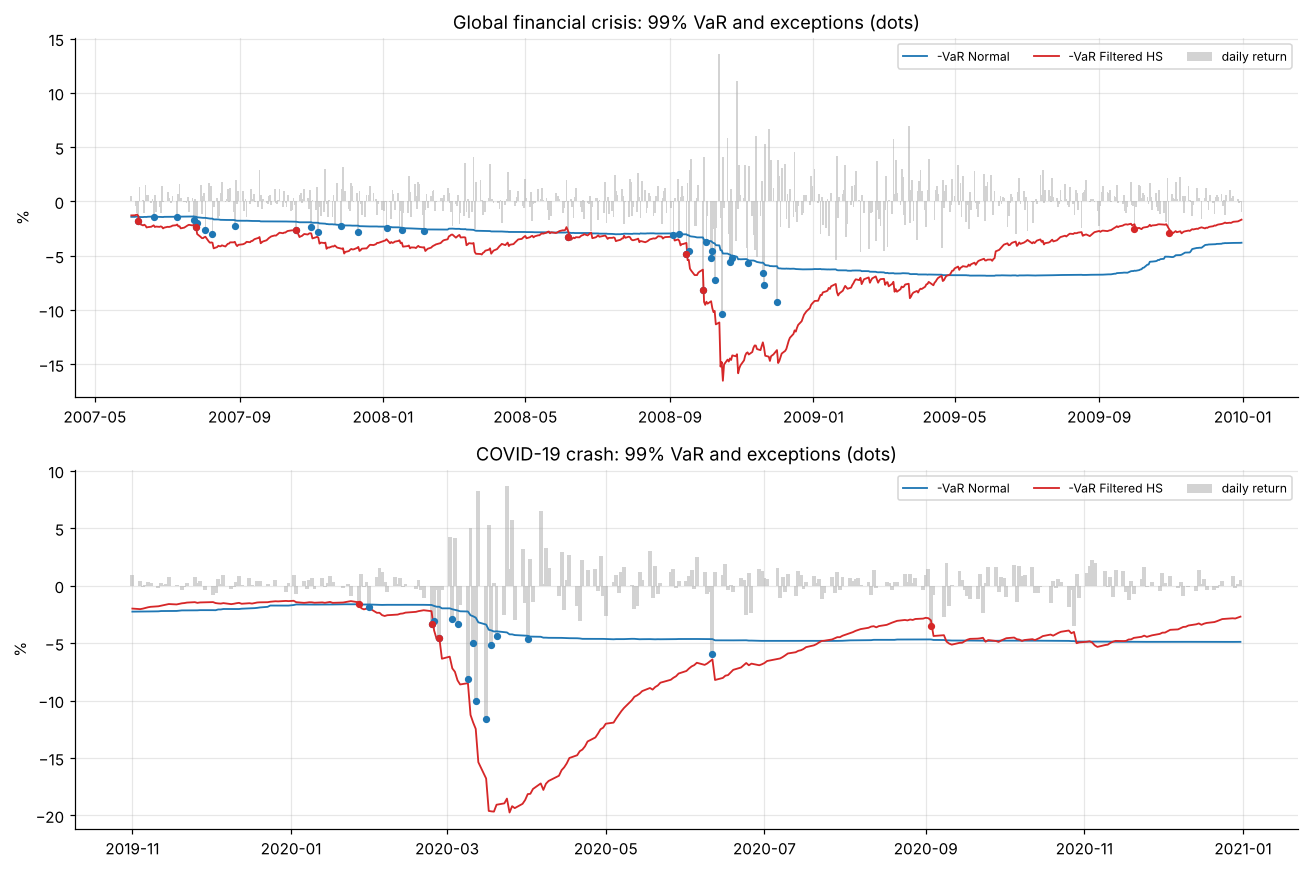

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(12, 8))
for ax, (s, e, title) in zip(axes, [("2007-06-01", "2009-12-31", "Global financial crisis"), ("2019-11-01", "2020-12-31", "COVID-19 crash")]):
    w = rr.loc[s:e]
    ax.bar(w.index, w * 100, color="lightgrey", width=1.5, label="daily return")
    for k, c in [("Normal", "tab:blue"), ("Filtered HS", "tab:red")]:
        v = models[k].loc[s:e]; ax.plot(-v * 100, color=c, lw=1.2, label=f"-VaR {k}")
        hit = w < -v; ax.scatter(w.index[hit], w[hit] * 100, color=c, s=14, zorder=3)
    ax.set_title(f"{title}: 99% VaR and exceptions (dots)"); ax.set_ylabel("%"); ax.legend(fontsize=8, ncol=3)
fig.tight_layout(); plt.savefig(IMG / "var_exceptions.png", bbox_inches="tight"); plt.show()

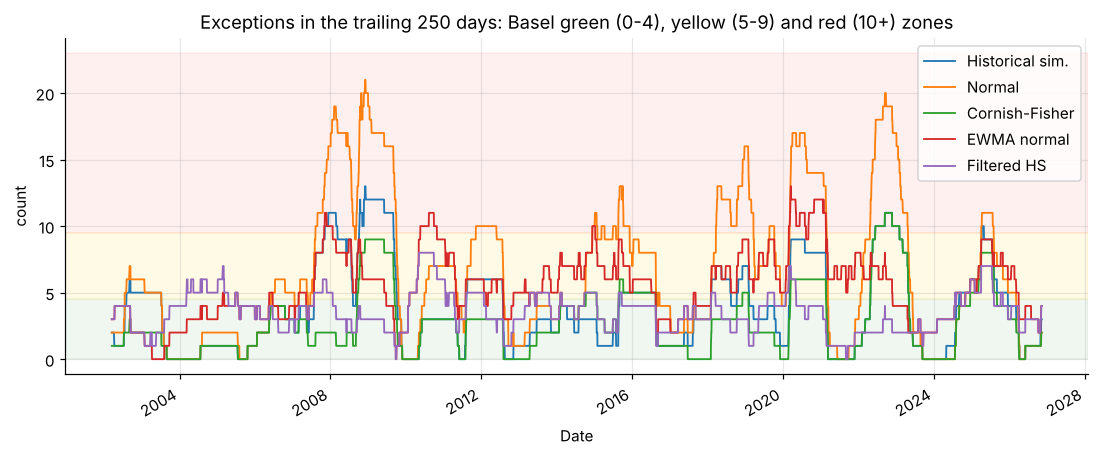

In [4]:
roll = pd.DataFrame({k: backtest.exceptions(rr, v).rolling(250).sum() for k, v in models.items()})
ax = roll.plot(figsize=(12, 4.5), lw=1.2)
ax.axhspan(0, 4.5, color="green", alpha=0.06); ax.axhspan(4.5, 9.5, color="gold", alpha=0.10); ax.axhspan(9.5, roll.max().max() + 2, color="red", alpha=0.06)
ax.set_title("Exceptions in the trailing 250 days: Basel green (0-4), yellow (5-9) and red (10+) zones"); ax.set_ylabel("count")
plt.savefig(IMG / "basel_traffic_light.png", bbox_inches="tight"); plt.show()

## Expected Shortfall: how bad are the bad days?

In [5]:
es_models = {"Historical sim.": var.historical(r)["ES"], "Normal": var.parametric_normal(r)["ES"], "Filtered HS": var.filtered_hs(r)["ES"]}
rows = {}
for k, es in es_models.items():
    v = models[k]; es = es.loc[start:]
    hit = rr < -v
    rows[k] = {"avg forecast ES": es[hit].mean(), "avg realised loss on exception days": -rr[hit].mean(),
               "ES ratio (realised / forecast)": -rr[hit].mean() / es[hit].mean()}
pd.DataFrame(rows).T.style.format({"avg forecast ES": "{:.2%}", "avg realised loss on exception days": "{:.2%}", "ES ratio (realised / forecast)": "{:.2f}"})

,avg forecast ES,avg realised loss on exception days,ES ratio (realised / forecast)
Historical sim.,3.27%,3.65%,1.12
Normal,2.61%,3.25%,1.24
Filtered HS,2.53%,2.62%,1.04


**Takeaways**
* **Normal VaR fails badly**: 2.5% exceptions instead of 1%. Daily equity returns have far fatter tails than a Gaussian.
* **Cornish-Fisher** gets the *number* of exceptions right (1.08%, Kupiec p = 0.50), but they **cluster** in crises (Christoffersen independence test rejects), and it still reaches the Basel red zone. Getting the average right is not enough.
* **Filtered HS** combines volatility scaling with fat empirical tails. It is the only model whose worst 250-day window stays out of the red zone, it has the least clustering, and its Expected Shortfall is best calibrated (realised/forecast ≈ 1.04).
* Every model fails the joint conditional-coverage test over 25 years, a reminder that no single VaR model is right in every regime. Pair them with stress tests.